In [1]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             roc_auc_score, precision_score, recall_score, f1_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
RANDOM_STATE = 42
DATA_PATH = Path("../data/viral_songs.csv")
ARTIFACTS = Path("../artifacts"); 
ARTIFACTS.mkdir(exist_ok=True)

In [2]:
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(10000, 17)


,track_id,track_name,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
0,track_00001,Track_00001,Artist_1519,Pop,2013,237,0.760,0.703,0.747,140.8,0.115,0.103,0.206,0.272,-9.41,661412,1
1,track_00002,Track_00002,Artist_0458,Electronic,2018,239,0.436,0.934,0.672,105.1,0.016,0.002,0.024,0.000,-9.89,1114175,1
2,track_00003,Track_00003,Artist_1386,Hip-Hop,2014,148,0.642,0.725,0.460,90.6,0.010,0.520,0.079,0.053,-5.53,105832,1
3,track_00004,Track_00004,Artist_0865,Classical,2012,216,0.326,0.456,0.299,71.3,0.966,0.042,0.000,0.074,-11.39,915397,0
4,track_00005,Track_00005,Artist_0192,Pop,2011,277,0.599,0.683,0.700,132.6,0.078,0.113,0.000,0.036,-5.56,3690733,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track_id          10000 non-null  str    
 1   track_name        10000 non-null  str    
 2   artist            10000 non-null  str    
 3   genre             10000 non-null  str    
 4   release_year      10000 non-null  int64  
 5   duration_sec      10000 non-null  int64  
 6   danceability      10000 non-null  float64
 7   energy            10000 non-null  float64
 8   valence           10000 non-null  float64
 9   tempo_bpm         10000 non-null  float64
 10  acousticness      10000 non-null  float64
 11  instrumentalness  10000 non-null  float64
 12  speechiness       10000 non-null  float64
 13  liveness          10000 non-null  float64
 14  loudness_db       10000 non-null  float64
 15  streams           10000 non-null  int64  
 16  viral             10000 non-null  int64  
dtypes: fl

In [4]:
rate = df["viral"].mean()
print(f"Вирусных треков: {df['viral'].sum()} из {len(df)} ({rate:.1%})")
df["viral"].value_counts()

Вирусных треков: 3605 из 10000 (36.0%)


viral
0    6395
1    3605
Name: count, dtype: int64

In [5]:
TARGET = "viral"
DROP = ["track_id", "streams", TARGET]
X = df.drop(columns=DROP)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(X_train.shape, X_test.shape)
print(f"доля вирусных: train {y_train.mean():.3f}, test {y_test.mean():.3f}")

(8000, 14) (2000, 14)
доля вирусных: train 0.360, test 0.360


In [6]:
numeric_cols = ["release_year", "duration_sec", "danceability", "energy", "valence", "tempo_bpm", "acousticness", "instrumentalness", "speechiness", "liveness", "loudness_db"]
categorical_cols = [c for c in X.columns if c not in numeric_cols]
print("числовые:", numeric_cols)
print("категориальные:", categorical_cols)

числовые: ['release_year', 'duration_sec', 'danceability', 'energy', 'valence', 'tempo_bpm', 'acousticness', 'instrumentalness', 'speechiness', 'liveness', 'loudness_db']
категориальные: ['track_name', 'artist', 'genre']


In [7]:
preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), numeric_cols),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_cols),
])

logreg = Pipeline([
    ("preprocess", preprocess),
    ("model", LogisticRegression(max_iter=1000, C=1.0)),
])
logreg.fit(X_train, y_train)

def report(name, y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    row = {
        "model": name,
        "ROC-AUC": roc_auc_score(y_true, proba),
        "PR-AUC": average_precision_score(y_true, proba),
        f"precision@{threshold}": precision_score(y_true, pred),
        f"recall@{threshold}": recall_score(y_true, pred),
        f"F1@{threshold}": f1_score(y_true, pred),
    }
    return row

proba_lr = logreg.predict_proba(X_test)[:, 1]
results = [report("logreg", y_test, proba_lr)]
pd.DataFrame(results).round(3)

,model,ROC-AUC,PR-AUC,precision@0.5,recall@0.5,F1@0.5
0,logreg,0.793,0.639,0.62,0.574,0.596


порог 0.400: recall 0.700, precision 0.586


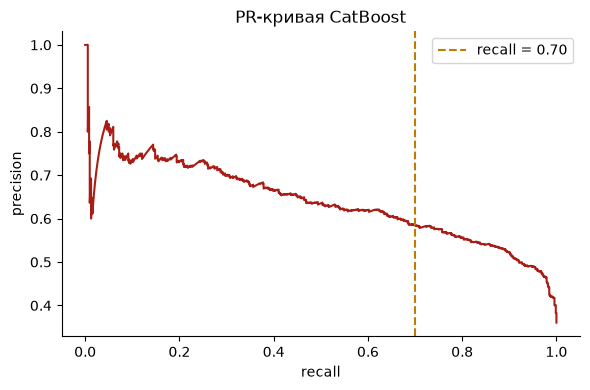

In [8]:
precision, recall, thresholds = precision_recall_curve(y_test, proba_lr)
mask = recall[:-1] >= 0.70
best_threshold = thresholds[mask].max()
pred = (proba_lr >= best_threshold).astype(int)
print(f"порог {best_threshold:.3f}: recall {recall_score(y_test, pred):.3f}, "
      f"precision {precision_score(y_test, pred):.3f}")

plt.figure(figsize=(6, 4))
plt.plot(recall, precision, color="#A81E17")
plt.axvline(0.70, color="#C07C00", linestyle="--", label="recall = 0.70")
plt.xlabel("recall"); plt.ylabel("precision"); plt.title("PR-кривая CatBoost")
plt.legend(); plt.gca().spines[["top", "right"]].set_visible(False)
plt.tight_layout()

In [9]:
import sklearn, catboost

metadata = {
    "model_name": "viral-logreg",
    "model_version": "0.1.0",
    "trained_at": pd.Timestamp.utcnow().isoformat(timespec="seconds"),
    "n_train": int(len(X_train)),
    "features": list(X.columns),
    "numeric_cols": numeric_cols,
    "categorical_cols": categorical_cols,
    "threshold": float(round(best_threshold, 4)),
    "metrics_test": {k: round(float(v), 4) for k, v in results[0].items() if k != "model"},
    "libs": {"pandas": pd.__version__, "scikit-learn": sklearn.__version__, "catboost": catboost.__version__},
}

joblib.dump({"pipeline": logreg, "metadata": {**metadata, "model_name": "churn-logreg"}},
            ARTIFACTS / "logreg_model.joblib")
(ARTIFACTS / "metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")

sorted(p.name for p in ARTIFACTS.iterdir())

['logreg_model.joblib', 'metadata.json']

In [10]:
results

[{'model': 'logreg',
  'ROC-AUC': np.float64(0.7931777491734072),
  'PR-AUC': np.float64(0.6388793233463164),
  'precision@0.5': 0.6197604790419161,
  'recall@0.5': 0.5742024965325936,
  'F1@0.5': 0.5961123110151187}]